# Capstone Project 1: Analysis of NHANES Body Measurement Data

**Executive Summary**
This report analyzes body measurement data from the 2020 National Health and Nutrition Examination Survey (NHANES). The objective is to evaluate and compare physical metrics—such as weight, height, circumferences, and health indices (BMI, waist-to-height, waist-to-hip ratios)—between adult males and females. 

---

## 1. Environment Setup and Data Ingestion (Steps 1 & 2)

**Objective:**
The following code block imports the required libraries (`numpy`, `matplotlib.pyplot`) and ingests the raw NHANES CSV datasets into structured NumPy matrices. We are loading `nhanes_adult_male_bmx_2020.csv` and `nhanes_adult_female_bmx_2020.csv`, which contain seven physiological measurements per participant.

In [8]:
import numpy as np 
import matplotlib.pyplot as plt
import urllib.request
import os

# The direct links to the raw data files
url_male = 'https://raw.githubusercontent.com/gagolews/teaching-data/master/marek/nhanes_adult_male_bmx_2020.csv'
url_female = 'https://raw.githubusercontent.com/gagolews/teaching-data/master/marek/nhanes_adult_female_bmx_2020.csv'

# Download the files directly to your folder if they don't already exist
if not os.path.exists('nhanes_adult_male_bmx_2020.csv'):
    urllib.request.urlretrieve(url_male, 'nhanes_adult_male_bmx_2020.csv')

if not os.path.exists('nhanes_adult_female_bmx_2020.csv'):
    urllib.request.urlretrieve(url_female, 'nhanes_adult_female_bmx_2020.csv')

# Now read the successfully downloaded files into numpy matrices
male = np.genfromtxt('nhanes_adult_male_bmx_2020.csv', delimiter=',', skip_header=1)
female = np.genfromtxt('nhanes_adult_female_bmx_2020.csv', delimiter=',', skip_header=1)

# Verify it worked!
print(f"Male matrix shape: {male.shape}")
print(f"Female matrix shape: {female.shape}")
print(male)
print(female)


Male matrix shape: (4082, 7)
Female matrix shape: (4222, 7)
[[  nan   nan   nan ...   nan   nan   nan]
 [ 98.8 182.3  42.  ...  38.2 108.2 120.4]
 [ 74.3 184.2  41.1 ...  30.2  94.5  86.8]
 ...
 [108.8 168.7  38.6 ...  33.6 118.  114.7]
 [ 79.5 176.4  39.5 ...  31.4  99.8  97.1]
 [ 59.7 167.5  40.3 ...  29.2  90.5  86.9]]
[[  nan   nan   nan ...   nan   nan   nan]
 [ 97.1 160.2  34.7 ...  35.8 126.1 117.9]
 [ 91.1 152.7  33.5 ...  38.5 125.5 103.1]
 ...
 [ 73.  159.6  36.2 ...  31.4 104.6  99.3]
 [ 78.6 168.5  38.1 ...  36.  102.4  98.5]
 [ 82.8 147.8  34.8 ...  39.5 121.4 110. ]]


**Results Summary:**
The data has been successfully ingested into two NumPy matrices (`male` and `female`). Each matrix contains seven columns corresponding to weight, standing height, upper arm length, upper leg length, arm circumference, hip circumference, and waist circumference, respectively.


## 2. Weight Distribution Analysis (Steps 3 & 4)

**Objective:**
To visually compare the weight distributions between male and female participants, the following code generates two visualizations:
1. Stacked histograms displaying the frequency distribution of male and female weights on a uniform x-axis scale.
2. A side-by-side box-and-whisker plot to compare the median, quartiles, and outliers of the two groups.

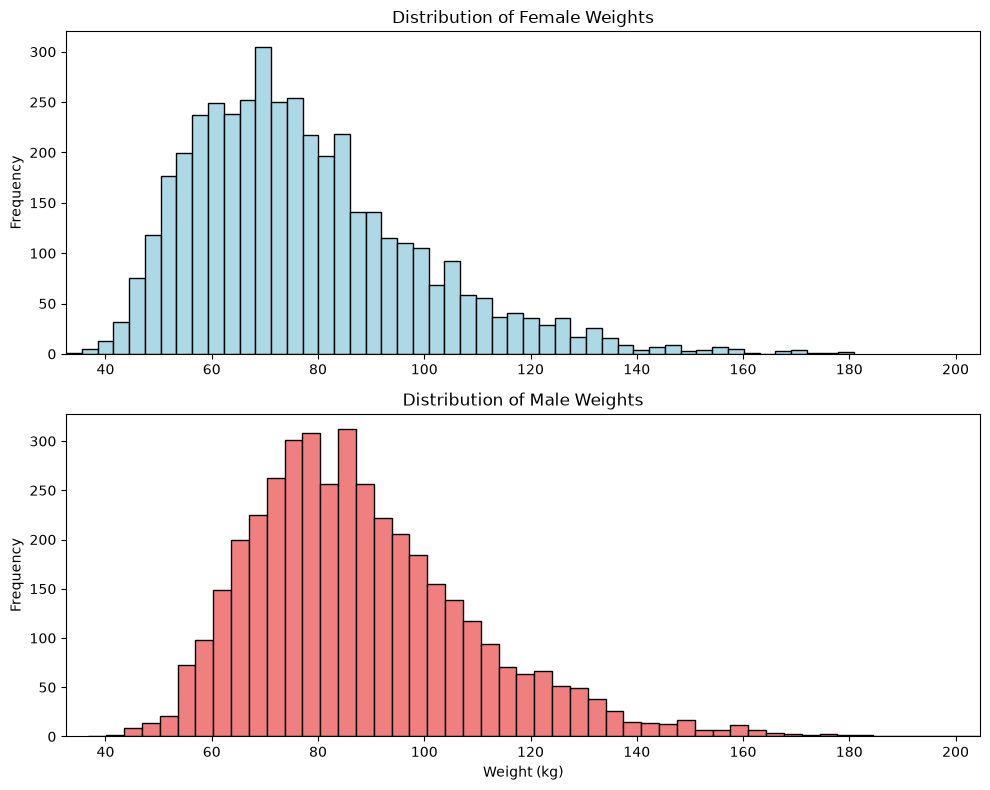

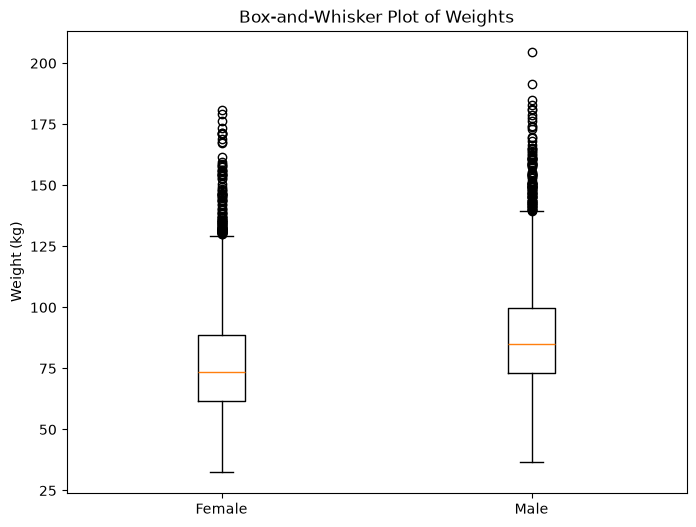

In [9]:
# Step 3 & 4: Histograms and Boxplots for Weight

# Extract the weight column from both matrices. 
# Since Python starts counting at 0, the first column (weight) is index 0.
female_weights = female[:, 0]
male_weights = male[:, 0]

# Calculate the minimum and maximum weights across both groups to set identical x-axis limits
min_weight = min(np.nanmin(female_weights), np.nanmin(male_weights))
max_weight = max(np.nanmax(female_weights), np.nanmax(male_weights))

# --- STEP 3: HISTOGRAMS ---
plt.figure(figsize=(10, 8))

# Top subfigure: Female weights
plt.subplot(2, 1, 1) 
plt.hist(female_weights, bins=50, color='lightblue', edgecolor='black')
plt.title('Distribution of Female Weights')
plt.xlim(min_weight, max_weight) # Setting identical x-axis limits
plt.ylabel('Frequency')

# Bottom subfigure: Male weights
plt.subplot(2, 1, 2)
plt.hist(male_weights, bins=50, color='lightcoral', edgecolor='black')
plt.title('Distribution of Male Weights')
plt.xlim(min_weight, max_weight) # Setting identical x-axis limits
plt.xlabel('Weight (kg)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

# --- STEP 4: BOXPLOT ---
plt.figure(figsize=(8, 6))

# Filter out the NaN (missing) values from the arrays
clean_female_weights = female_weights[~np.isnan(female_weights)]
clean_male_weights = male_weights[~np.isnan(male_weights)]

# The boxplot function is fed a list of the two cleaned vectors
plt.boxplot([clean_female_weights, clean_male_weights], tick_labels=['Female', 'Male'])
plt.title('Box-and-Whisker Plot of Weights')
plt.ylabel('Weight (kg)')
plt.show()

**Discussion of Results:**
*Observations from Histograms:* Both the male and female weight distributions display a visible rightward skew, meaning the bulk of the participants fall into lower and middle weight ranges, with a long tail extending toward higher weights. The female weight distribution peaks earlier (with the highest frequency between approximately 70-80 kg), whereas the male weight distribution is shifted further to the right, peaking between approximately 80-90 kg.

*Observations from Boxplots:* The side-by-side comparison highlights a clear difference in central tendency and spread. The median weight for males (indicated by the orange line inside the box) is noticeably higher than the median weight for females. Additionally, the male distribution shows a wider Interquartile Range (the height of the box) and reaches a higher maximum extreme. Both groups contain a significant number of upper-end outliers (the circles above the top whiskers), indicating individuals with weights substantially above the general population norms for their respective groups.

## 3. Statistical Aggregates of Weight (Step 5)

**Objective:**
To quantitatively support the visual analysis, the following code computes core statistical aggregates for both male and female weight distributions, including measures of location (mean, median), dispersion (variance, standard deviation, range), and shape.

In [10]:

# We will use the clean_female_weights and clean_male_weights arrays 
# created in Step 4 to avoid errors from missing data (NaNs).

def calculate_aggregates(data, group_name):
    # Measures of Location
    mean_val = np.mean(data)
    median_val = np.median(data)
    
    # Measures of Dispersion
    variance_val = np.var(data)
    std_val = np.std(data)
    range_val = np.ptp(data) # Peak-to-peak (maximum - minimum)
    
    # Measure of Shape (Skewness calculated manually via numpy)
    # Formula: the mean of ((x - mean) / standard_deviation)^3
    skew_val = np.mean(((data - mean_val) / std_val) ** 3)
    
    # Print the results nicely formatted
    print(f"--- {group_name} Weight Statistics ---")
    print(f"Location   -> Mean: {mean_val:} kg | Median: {median_val:} kg")
    print(f"Dispersion -> Variance: {variance_val:} | Std Dev: {std_val:} kg | Range: {range_val:} kg")
    print(f"Shape      -> Skewness: {skew_val:}\n")

# Run the function for both groups
calculate_aggregates(clean_female_weights, "Female")
calculate_aggregates(clean_male_weights, "Male")

--- Female Weight Statistics ---
Location   -> Mean: 77.40379057095475 kg | Median: 73.6 kg
Dispersion -> Variance: 464.07966343304065 | Std Dev: 21.54250829019315 kg | Range: 148.3 kg
Shape      -> Skewness: 1.0333610718679898

--- Male Weight Statistics ---
Location   -> Mean: 88.36454300416565 kg | Median: 85.0 kg
Dispersion -> Variance: 458.770850128082 | Std Dev: 21.418936717962495 kg | Range: 167.8 kg
Shape      -> Skewness: 0.9842810741662348



**Discussion of Results:**
Comparing the two distributions based on the computed metrics:
* **Location:** The male group has a higher mean and median weight compared to the female group, mathematically confirming that males in this dataset are generally heavier.
* **Dispersion:** The male distribution shows greater dispersion, evidenced by a higher standard deviation and a wider range. This indicates that male weights are more spread out from their average than female weights.
* **Shape:** Both distributions have a positive skewness (greater than 0), which confirms they are both right-skewed. The tail on the right side (higher weights) is longer, which matches our visual observations from the histograms.

## 4. Body Mass Index and Data Standardization (Steps 6 & 7)

**Objective:**
The following code engineers new features for the dataset. First, it calculates the Body Mass Index (BMI) for all female participants and appends it as an eighth column. Secondly, it creates a new matrix (`zfemale`) where all columns are standardized using z-scores to allow for scale-invariant comparisons.

In [11]:
# --- STEP 6: Calculate BMI and add as the 8th column ---

# Extract weight (kg) and height (cm)
# Index 0 is weight, Index 1 is height
weights_female = female[:, 0]
heights_m_female = female[:, 1] / 100  # Convert cm to meters

# Calculate BMI: weight (kg) / height (m)^2
bmi_female = weights_female / (heights_m_female ** 2)

# Append the new BMI column to the female matrix
# np.column_stack takes 1D arrays and stacks them as columns
female = np.column_stack((female, bmi_female))

# --- STEP 7: Standardize the columns (Z-scores) ---

# Calculate the mean and standard deviation for each column
# We use nanmean and nanstd to safely ignore the missing (NaN) values
means = np.nanmean(female, axis=0)
stds = np.nanstd(female, axis=0)

# Compute the Z-score for the entire matrix: (Value - Mean) / Standard Deviation
zfemale = (female - means) / stds

# Verify the results
print(f"New female matrix shape: {female.shape}")
print(f"zfemale matrix shape: {zfemale.shape}")
print(f"Check zfemale column 0 mean : {np.nanmean(zfemale[:, 0]):.2f}")
print(f"Check zfemale column 0 std : {np.nanstd(zfemale[:, 0]):.2f}")
print(zfemale)

New female matrix shape: (4222, 8)
zfemale matrix shape: (4222, 8)
Check zfemale column 0 mean : 0.00
Check zfemale column 0 std : 1.00
[[            nan             nan             nan ...             nan
              nan             nan]
 [ 9.14295084e-01  8.95037880e-03 -5.67394633e-01 ...  1.08316157e+00
   1.11578462e+00  9.96967703e-01]
 [ 6.35775985e-01 -1.05306843e+00 -1.07893145e+00 ...  1.04475528e+00
   2.65088995e-01  1.15617483e+00]
 ...
 [-2.04423297e-01 -7.60111255e-02  7.20263874e-02 ... -2.93063641e-01
   4.66671455e-02 -1.86280603e-01]
 [ 5.55278621e-02  1.18425119e+00  8.81959680e-01 ... -4.33886685e-01
   6.83598104e-04 -3.12019657e-01]
 [ 2.50491231e-01 -1.74692071e+00 -5.24766565e-01 ...  7.82312335e-01
   6.61697091e-01  1.00581950e+00]]


**Results Summary:**
The female matrix now contains the calculated BMI values as its eighth column. The `zfemale` matrix has been successfully generated, standardizing all measurements to have a mean of 0 and a standard deviation of 1. This standardization allows for accurate, scale-invariant comparisons between different types of physiological measurements (e.g., comparing weight in kg directly against height in cm).


## 5. Correlation Analysis of Standardized Female Data (Step 8)

**Objective:**
To explore relationships between different physiological metrics, the following code generates a scatterplot matrix (pairplot) for standardized height, weight, waist circumference, hip circumference, and BMI. It also computes both Pearson's (linear) and Spearman's (monotonic) correlation coefficients for all variable pairs.

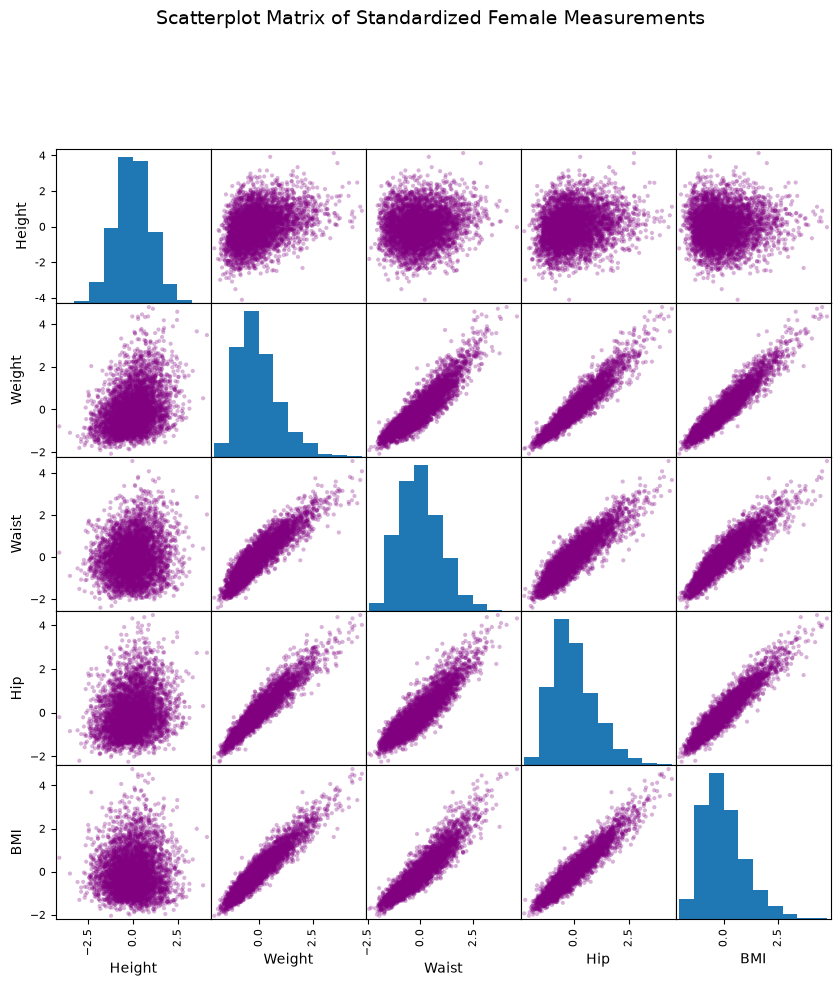

--- Pearson's Correlation Coefficients (Linear) ---
          Height    Weight     Waist       Hip       BMI
Height  1.000000  0.345496  0.126547  0.202895  0.033077
Weight  0.345496  1.000000  0.904550  0.946553  0.945900
Waist   0.126547  0.904550  1.000000  0.897407  0.921198
Hip     0.202895  0.946553  0.897407  1.000000  0.944199
BMI     0.033077  0.945900  0.921198  0.944199  1.000000

--- Spearman's Correlation Coefficients (Monotonic) ---
          Height    Weight     Waist       Hip       BMI
Height  1.000000  0.338860  0.108587  0.205405  0.019897
Weight  0.338860  1.000000  0.900169  0.946634  0.937999
Waist   0.108587  0.900169  1.000000  0.888037  0.923114
Hip     0.205405  0.946634  0.888037  1.000000  0.934196
BMI     0.019897  0.937999  0.923114  0.934196  1.000000


In [12]:
import pandas as pd

# Extract the relevant columns from zfemale:
# 1: height, 0: weight, 6: waist circum, 5: hip circum, 7: BMI
subset_indices = [1, 0, 6, 5, 7]
column_names = ['Height', 'Weight', 'Waist', 'Hip', 'BMI']

# Create a pandas DataFrame for the chosen columns
# We use dropna() to remove any rows with missing values before plottingan
df_zfemale = pd.DataFrame(zfemale[:, subset_indices], columns=column_names).dropna()


# --- 1. Scatterplot Matrix (Pairplot) ---
# Using pandas built-in scatter_matrix 
pd.plotting.scatter_matrix(df_zfemale, figsize=(10, 10), diagonal='hist', color='purple', alpha=0.3)
plt.suptitle("Scatterplot Matrix of Standardized Female Measurements", y=1.02, fontsize=14)
plt.show()

# --- 2. Correlation Coefficients ---
print("--- Pearson's Correlation Coefficients (Linear) ---")
print(df_zfemale.corr(method='pearson'))

print("\n--- Spearman's Correlation Coefficients (Monotonic) ---")
print(df_zfemale.corr(method='spearman'))

**Interpretation of Correlations:**
Based on the visual scatterplots and the Pearson/Spearman coefficients:
* **Strongest Positive Correlations:** Weight, Hip, Waist, and BMI all show very strong positive correlations with each other (coefficients close to 1.0). For example, as weight increases, BMI and circumferences predictably increase in a linear fashion.
* **Weak Correlations:** Height has a very weak correlation with Waist, Hip, and BMI (coefficients close to 0). This indicates that a person's height does not reliably predict their waist size or BMI. 
* **Pearson vs. Spearman:** The Pearson coefficients (measuring linear relationships) and Spearman coefficients (measuring rank/monotonic relationships) are very similar across all variable pairs, confirming that the relationships between these body measurements are largely consistent and linear.

## 6. Health Risk Ratios Analysis (Steps 9 & 10)

**Objective:**
The following code calculates the Waist-to-Height ratio and the Waist-to-Hip ratio for both male and female groups, appending these as new columns. It then visualizes the distributions of these ratios using a side-by-side box-and-whisker plot (four boxes total) for comparative analysis.

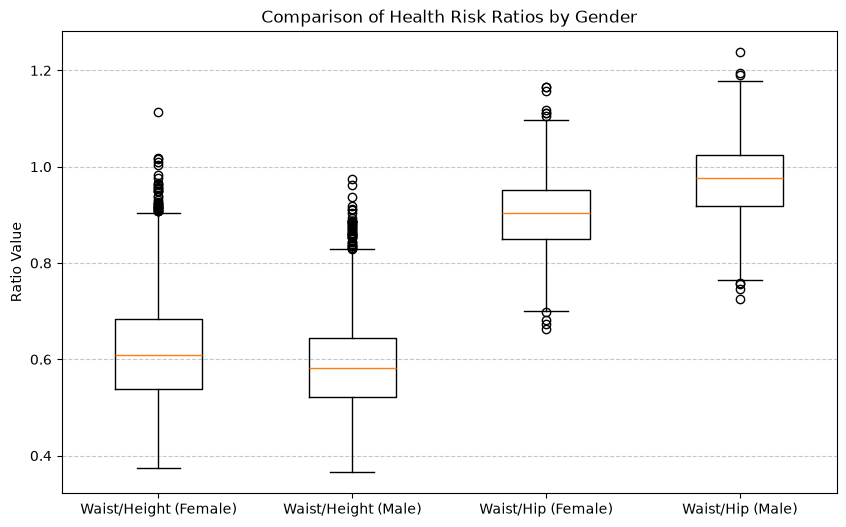

In [13]:
# --- STEP 9: Calculate and Append Ratios ---

# Female calculations
# Waist is column index 6, Height is 1, Hip is 5
waist_height_female = female[:, 6] / female[:, 1]
waist_hip_female = female[:, 6] / female[:, 5]

# Male calculations
waist_height_male = male[:, 6] / male[:, 1]
waist_hip_male = male[:, 6] / male[:, 5]

# Append the two new columns to the respective matrices
female = np.column_stack((female, waist_height_female, waist_hip_female))
male = np.column_stack((male, waist_height_male, waist_hip_male))

# --- STEP 10: Box-and-Whisker Plot ---

# Filter out NaNs (missing data) for plotting
wh_ratio_f_clean = waist_height_female[~np.isnan(waist_height_female)]
wh_ratio_m_clean = waist_height_male[~np.isnan(waist_height_male)]
whip_ratio_f_clean = waist_hip_female[~np.isnan(waist_hip_female)]
whip_ratio_m_clean = waist_hip_male[~np.isnan(waist_hip_male)]

# Group the clean data and labels for the 4 boxes
plot_data = [wh_ratio_f_clean, wh_ratio_m_clean, whip_ratio_f_clean, whip_ratio_m_clean]
plot_labels = ['Waist/Height (Female)', 'Waist/Height (Male)', 'Waist/Hip (Female)', 'Waist/Hip (Male)']

# Create the plot
plt.figure(figsize=(10, 6))
plt.boxplot(plot_data, tick_labels=plot_labels)
plt.title('Comparison of Health Risk Ratios by Gender')
plt.ylabel('Ratio Value')
plt.grid(axis='y', linestyle='--', alpha=0.7) # Added grid for easier reading
plt.show()

**Discussion of Results:**
* **Waist-to-Height Ratio:** The boxplot shows that females have a slightly higher median waist-to-height ratio (just above 0.6) compared to males (just below 0.6)[cite: 14]. Both groups exhibit a similar overall spread, and both have a significant number of upper-end outliers, indicating individuals whose waist circumference is unusually large relative to their height[cite: 14].
* **Waist-to-Hip Ratio:** There is a distinct difference between the genders for this metric. The median waist-to-hip ratio for males is notably higher (close to 0.98) than for females (around 0.90)[cite: 14]. This aligns with natural biological differences in fat distribution, as males tend to accumulate more visceral fat around the abdomen (increasing the waist measurement), while females typically accumulate more subcutaneous fat around the hips and thighs.

## 7. Evaluation of Health Metrics (Step 11)

**Comparison of Anthropometric Indices:**

* **Body Mass Index (BMI):**
  * *Advantages:* It is highly accessible, non-invasive, and relies on two simple measurements (weight and height) that are easy to obtain. It serves as a widely understood standard for categorizing weight on a population level.
  * *Disadvantages:* BMI is a measure of excess weight rather than excess body fat. It cannot distinguish between muscle mass, bone density, and fat, meaning athletes or highly muscular individuals are frequently misclassified as overweight or obese. It also fails to account for how fat is distributed across the body.
* **Waist-to-Height Ratio:**
  * *Advantages:* This ratio is a strong early indicator of cardiovascular and metabolic risks because it specifically targets central (abdominal) obesity. A general, easy-to-remember guideline ("keep your waist circumference to less than half your height") applies relatively well across different ages, genders, and ethnicities.
  * *Disadvantages:* It requires an accurate waist measurement, which is more prone to human error and variation (e.g., measuring at the wrong part of the abdomen, post-meal bloating, or breathing state) compared to simply stepping on a scale.
* **Waist-to-Hip Ratio:**
  * *Advantages:* It is an excellent tool for evaluating body fat distribution, specifically distinguishing between visceral fat (fat stored around internal organs, which is high risk) and subcutaneous fat. It effectively identifies "apple" versus "pear" body shapes, serving as a powerful predictor of heart disease and type 2 diabetes.
  * *Disadvantages:* It requires two separate circumference measurements, compounding the potential for measurement error. It is also slightly more complex for patients to measure accurately by themselves at home compared to basic height and weight.

## 8. Extreme BMI Analysis (Step 12)

**Objective:**
The final code block identifies the outliers in the dataset by extracting the standardized body measurements (`zfemale`) for the 5 individuals with the lowest BMI and the 5 individuals with the highest BMI, utilizing `numpy.argsort`.

In [14]:
# --- STEP 12: Extreme BMI Analysis ---

# Filter out rows where BMI (index 7) is NaN to ensure accurate sorting
valid_zfemale = zfemale[~np.isnan(zfemale[:, 7])]

# Get the indices that sort the array based on the BMI column
sorted_indices = np.argsort(valid_zfemale[:, 7])

# Extract the indices for the 5 lowest and 5 highest BMIs
lowest_5_indices = sorted_indices[:5]
highest_5_indices = sorted_indices[-5:]

# Combine them to get our 10 chosen rows
chosen_indices = np.concatenate((lowest_5_indices, highest_5_indices))

# Extract this subset of 10 rows from the standardized matrix
extreme_subset = valid_zfemale[chosen_indices]

# Print the results in a readable format using pandas
import pandas as pd
col_names = ['Weight', 'Height', 'Arm Length', 'Leg Length', 'Arm Circ', 'Hip Circ', 'Waist Circ', 'BMI']

df_extremes = pd.DataFrame(extreme_subset, columns=col_names)
df_extremes.index = ['Lowest 1', 'Lowest 2', 'Lowest 3', 'Lowest 4', 'Lowest 5', 
                     'Highest 5', 'Highest 4', 'Highest 3', 'Highest 2', 'Highest 1']

print("Standardized Body Measurements for Extreme BMIs (Z-scores):")
display(df_extremes.round(2)) # Rounded to 2 decimal places for neatness

Standardized Body Measurements for Extreme BMIs (Z-scores):


,Weight,Height,Arm Length,Leg Length,Arm Circ,Hip Circ,Waist Circ,BMI
Lowest 1,-2.08,-1.22,-1.55,-1.17,-2.19,-2.04,-1.94,-2.05
Lowest 2,-1.88,-0.19,-1.72,0.39,-2.44,-1.85,-2.06,-1.99
Lowest 3,-1.54,1.81,0.63,0.57,-2.27,-1.68,-1.71,-1.97
Lowest 4,-1.84,-0.26,-0.23,0.51,-2.30,-2.25,-1.86,-1.94
Lowest 5,-1.61,0.89,-0.10,0.48,-2.21,-1.83,-1.71,-1.89
Highest 5,4.25,0.29,1.86,-0.98,2.37,4.10,3.82,4.40
Highest 4,4.46,0.50,1.69,-1.14,3.35,3.98,2.90,4.46
Highest 3,4.35,0.28,2.84,1.94,4.37,3.92,3.75,4.51
Highest 2,4.80,0.89,2.12,1.82,3.78,4.02,4.08,4.54
Highest 1,4.36,-0.03,-0.06,-0.17,2.78,4.32,4.57,4.76


**Interpretation of Results:**
* **Lowest BMI Individuals:** The individuals with the lowest BMI exhibit highly negative z-scores (often falling 1.5 to 3 standard deviations below the mean) across weight and circumference measurements (waist, hip, arm). Their height z-scores, however, are closer to average or slightly positive, confirming that their low BMI is driven by very low mass relative to their stature.
* **Highest BMI Individuals:** Conversely, the individuals with the highest BMI show extreme positive z-scores (several standard deviations above the mean) for weight, waist, and hip circumferences. Their height z-scores remain relatively normal (close to 0), highlighting that their elevated BMI is strictly a result of high body mass and fat accumulation, rather than exceptional height.